# 03 · Data-Format Benchmarks — *from scratch*

**Phase goal:** decide how to *store* tabular data by actually **measuring** the
size ↔ speed trade-off on *this* dataset — not guessing from blog posts.

A **CSV** is human-readable and opens in Excel, but it is large and forgets your
column types. **Columnar binary formats** (Parquet, Feather) are smaller and/or
much faster and remember dtypes — at the cost of readability. We'll write the
same DataFrame in several formats and time each one, all in plain Python.

In [1]:
import time
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "../data/raw/cars24-car-price-cleaned-new.csv.gz"


def clean(df):
    """Minimal clean (same as nb 02) so this notebook stands alone."""
    df = df.rename(columns={"5": "Seats_5", ">5": "Seats_Above_5"})
    df = df.dropna(subset=["selling_price"])
    df = df[df["selling_price"] > 0].dropna()
    for col in ["make", "model"]:
        df[col] = df[col].astype(str).str.strip().str.upper()
    return df.reset_index(drop=True)


df = clean(pd.read_csv(DATA_PATH))
print("benchmarking on", df.shape[0], "rows x", df.shape[1], "columns")

benchmarking on 19820 rows x 17 columns


### The benchmark, written out
For each format we (1) write the file and time it, (2) record the file size, and
(3) read it back a few times and keep the **fastest** read (the fairest measure —
it removes one-off noise from the operating system).

In [2]:
OUT_DIR = Path("../data/processed/_bench_basics")
OUT_DIR.mkdir(parents=True, exist_ok=True)


def fastest_read(reader, path, repeats=5):
    """Read `path` `repeats` times with `reader`; return the fastest time (s)."""
    best = float("inf")
    for _ in range(repeats):
        t = time.perf_counter()
        reader(path)
        best = min(best, time.perf_counter() - t)
    return best


# Each entry: (label, filename, how-to-write, how-to-read)
formats = [
    ("csv",       "b.csv",          lambda p: df.to_csv(p, index=False),                    pd.read_csv),
    ("csv_gzip",  "b.csv.gz",       lambda p: df.to_csv(p, index=False, compression="gzip"), pd.read_csv),
    ("csv_bz2",   "b.csv.bz2",      lambda p: df.to_csv(p, index=False, compression="bz2"),  pd.read_csv),
    ("parquet",   "b.parquet",      lambda p: df.to_parquet(p, compression="snappy"),        pd.read_parquet),
    ("feather",   "b.feather",      lambda p: df.to_feather(p),                              pd.read_feather),
]

results = {}
for label, fname, write, read in formats:
    path = OUT_DIR / fname
    t = time.perf_counter()
    write(path)
    write_s = time.perf_counter() - t
    results[label] = {
        "bytes":    path.stat().st_size,
        "write_ms": round(write_s * 1000, 1),
        "read_ms":  round(fastest_read(read, path) * 1000, 1),
    }

# Turn the raw numbers into a friendly comparison table.
tbl = pd.DataFrame(results).T
tbl["KB"]     = (tbl["bytes"] / 1024).round(0)
tbl["vs_csv"] = (tbl["bytes"] / tbl.loc["csv", "bytes"] * 100).round(1)   # % of CSV size
tbl = tbl[["KB", "vs_csv", "write_ms", "read_ms"]]
tbl

,KB,vs_csv,write_ms,read_ms
csv,1535.0,100.0,73.4,22.5
csv_gzip,290.0,18.9,303.3,25.4
csv_bz2,151.0,9.9,190.8,66.8
parquet,272.0,17.7,72.0,7.4
feather,867.0,56.5,16.6,7.7


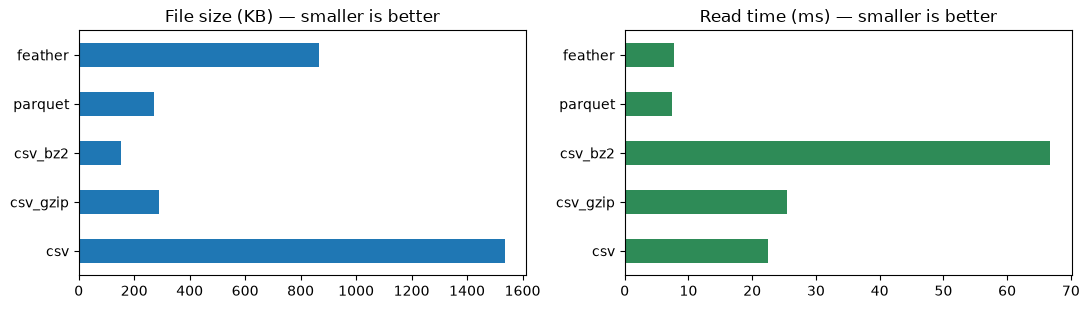

In [3]:
# Visualise the two things we care about most: file size and read speed.
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
tbl["KB"].plot.barh(ax=ax[0], title="File size (KB) — smaller is better")
tbl["read_ms"].plot.barh(ax=ax[1], color="seagreen", title="Read time (ms) — smaller is better")
plt.tight_layout()
plt.show()

### Takeaways
- **`CSV + gzip`** — several times smaller than raw CSV, still read directly by
  pandas. The best *low-friction* way to shrink a CSV for a git repo (which is
  exactly why this project stores its raw data as `.csv.gz`).
- **Parquet** — very small **and** the fastest binary read here, and it keeps
  dtypes. The right default for real data pipelines and larger datasets.
- **Feather** — extremely fast reads but larger files; good for short-lived
  local hand-offs between steps.
- **`CSV + bz2`** — usually the smallest on disk but the slowest to read; reserve
  it for cold archival.

> **Rule of thumb:** ship/share as **gzip CSV** (tiny + universal); compute over
> **Parquet** (small + fast + typed).